## Q1. Regression on California Housing Dataset :-
### DT regressor, Lasso,ridge, linear Regression, SVR, RF regressor,  KNN regressor

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [3]:
df=pd.read_csv("california_housing (1).csv")
print(df.head())

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                  41          880           129.0   
1    -122.22     37.86                  21         7099          1106.0   
2    -122.24     37.85                  52         1467           190.0   
3    -122.25     37.85                  52         1274           235.0   
4    -122.25     37.85                  52         1627           280.0   

   population  households  median_income ocean_proximity  median_house_value  
0         322         126         8.3252        NEAR BAY              452600  
1        2401        1138         8.3014        NEAR BAY              358500  
2         496         177         7.2574        NEAR BAY              352100  
3         558         219         5.6431        NEAR BAY              341300  
4         565         259         3.8462        NEAR BAY              342200  


### Preprocessing and EDA 

In [4]:
# 1. Null values check
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
ocean_proximity         0
median_house_value      0
dtype: int64


In [4]:
# Check duplicates
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


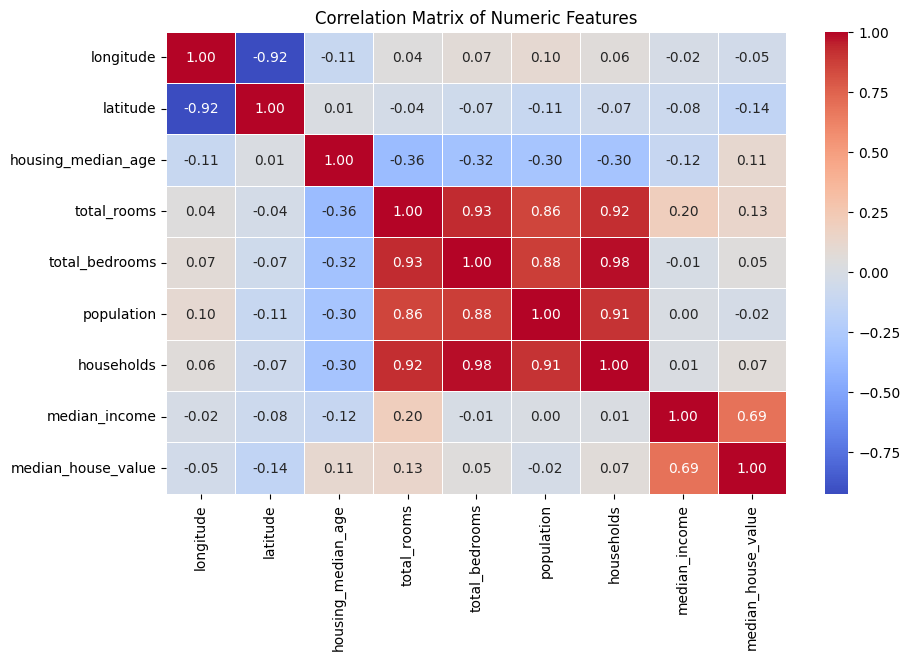

In [5]:
# Cell 2: EDA - Correlation Matrix
plt.figure(figsize=(10, 6))
numeric_df = df.drop(columns=['ocean_proximity'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Numeric Features")
plt.show()

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

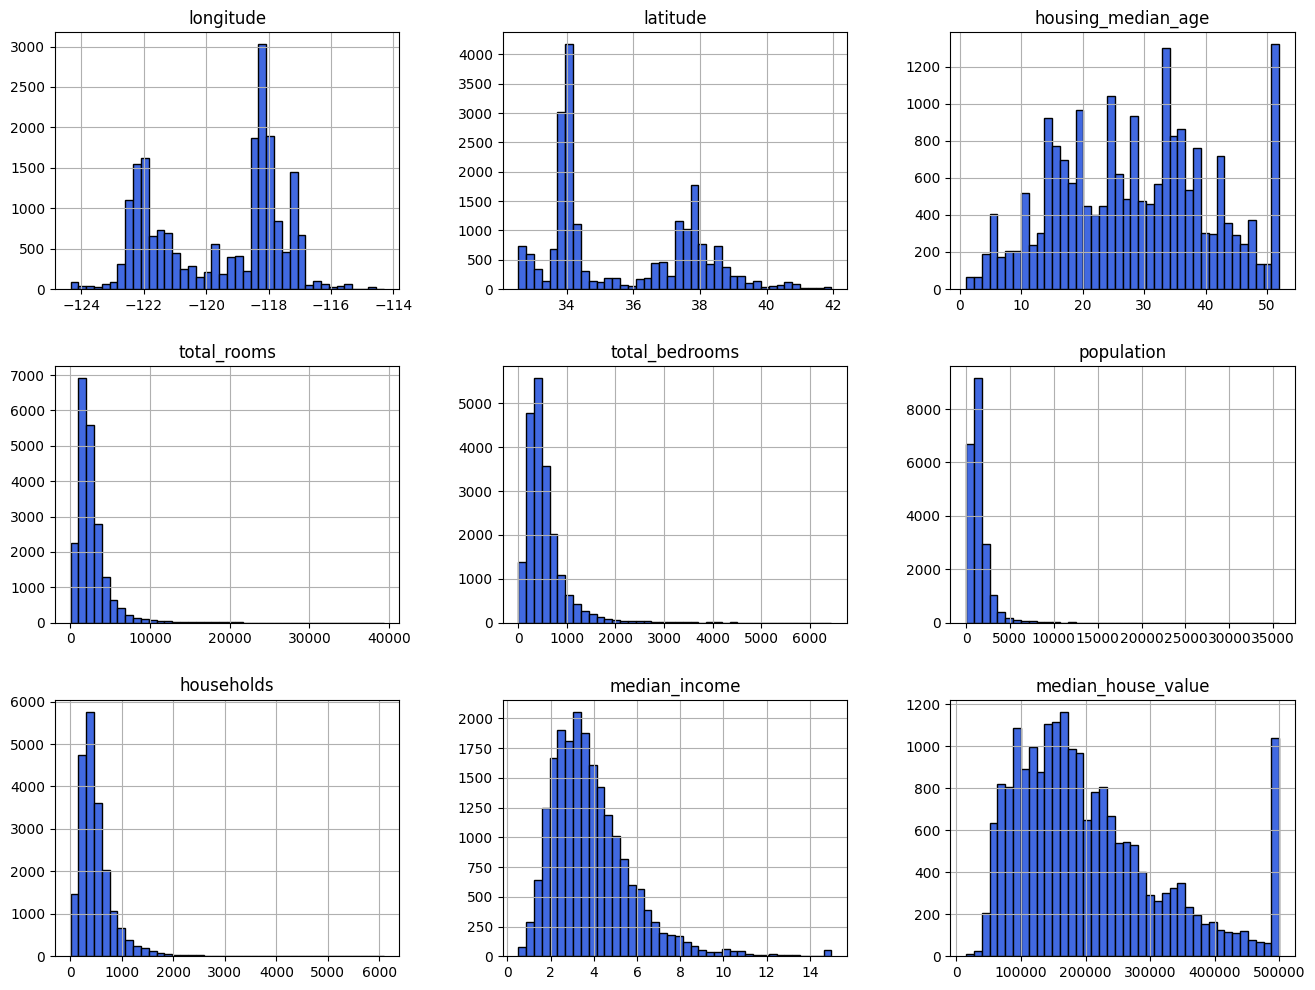

In [6]:
df.hist(bins=40, figsize=(16, 12), color='royalblue', edgecolor='black')

In [16]:
# Handle total_bedrooms by imputing median
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

In [17]:
# Create the ratio (Bedrooms per Room)
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']

# Drop the redundant raw total_bedrooms column to kill multicollinearity
df = df.drop(columns=['total_bedrooms'])

In [18]:
df.head(50)

,longitude,latitude,housing_median_age,total_rooms,population,households,median_income,ocean_proximity,median_house_value,bedrooms_per_room
0,-122.23,37.88,41,880,322,126,8.3252,NEAR BAY,452600,0.146591
1,-122.22,37.86,21,7099,2401,1138,8.3014,NEAR BAY,358500,0.155797
2,-122.24,37.85,52,1467,496,177,7.2574,NEAR BAY,352100,0.129516
3,-122.25,37.85,52,1274,558,219,5.6431,NEAR BAY,341300,0.184458
4,-122.25,37.85,52,1627,565,259,3.8462,NEAR BAY,342200,0.172096
5,-122.25,37.85,52,919,413,193,4.0368,NEAR BAY,269700,0.231774
6,-122.25,37.84,52,2535,1094,514,3.6591,NEAR BAY,299200,0.192899
7,-122.25,37.84,52,3104,1157,647,3.1200,NEAR BAY,241400,0.221327
8,-122.26,37.84,42,2555,1206,595,2.0804,NEAR BAY,226700,0.260274
9,-122.25,37.84,52,3549,1551,714,3.6912,NEAR BAY,261100,0.199211


In [19]:
# Check counts of all categories across the whole dataset
print(df['ocean_proximity'].value_counts())

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


In [20]:
print(df.head())

   longitude  latitude  housing_median_age  total_rooms  population  \
0    -122.23     37.88                  41          880         322   
1    -122.22     37.86                  21         7099        2401   
2    -122.24     37.85                  52         1467         496   
3    -122.25     37.85                  52         1274         558   
4    -122.25     37.85                  52         1627         565   

   households  median_income ocean_proximity  median_house_value  \
0         126         8.3252        NEAR BAY              452600   
1        1138         8.3014        NEAR BAY              358500   
2         177         7.2574        NEAR BAY              352100   
3         219         5.6431        NEAR BAY              341300   
4         259         3.8462        NEAR BAY              342200   

   bedrooms_per_room  
0           0.146591  
1           0.155797  
2           0.129516  
3           0.184458  
4           0.172096  


In [21]:
# Rooms per household
df['rooms_per_household'] = df['total_rooms'] / df['households']

# Population per household (occupancy density)
df['population_per_household'] = df['population'] / df['households']

In [22]:
# Drop raw columns to remove multicollinearity
df = df.drop(columns=['total_rooms', 'total_bedrooms', 'households'], errors='ignore')

In [23]:
print(df.head())

   longitude  latitude  housing_median_age  population  median_income  \
0    -122.23     37.88                  41         322         8.3252   
1    -122.22     37.86                  21        2401         8.3014   
2    -122.24     37.85                  52         496         7.2574   
3    -122.25     37.85                  52         558         5.6431   
4    -122.25     37.85                  52         565         3.8462   

  ocean_proximity  median_house_value  bedrooms_per_room  rooms_per_household  \
0        NEAR BAY              452600           0.146591             6.984127   
1        NEAR BAY              358500           0.155797             6.238137   
2        NEAR BAY              352100           0.129516             8.288136   
3        NEAR BAY              341300           0.184458             5.817352   
4        NEAR BAY              342200           0.172096             6.281853   

   population_per_household  
0                  2.555556  
1             

In [24]:
#onehot encoding for categorical variable 'ocean_proximity'
df = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True, dtype=int)

print(df.head())

   longitude  latitude  housing_median_age  population  median_income  \
0    -122.23     37.88                  41         322         8.3252   
1    -122.22     37.86                  21        2401         8.3014   
2    -122.24     37.85                  52         496         7.2574   
3    -122.25     37.85                  52         558         5.6431   
4    -122.25     37.85                  52         565         3.8462   

   median_house_value  bedrooms_per_room  rooms_per_household  \
0              452600           0.146591             6.984127   
1              358500           0.155797             6.238137   
2              352100           0.129516             8.288136   
3              341300           0.184458             5.817352   
4              342200           0.172096             6.281853   

   population_per_household  ocean_proximity_INLAND  ocean_proximity_ISLAND  \
0                  2.555556                       0                       0   
1           

## Train Test

In [25]:
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Applying algo : DT, SVR, RF regressor,  KNN regressor, Lasso, Ridge and linear Regression

In [20]:

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "KNN": KNeighborsRegressor(n_neighbors=5)
}

predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions[name] = model.predict(X_test_scaled)
    print(f"{name} trained successfully")


Linear Regression trained successfully
Ridge trained successfully
Lasso trained successfully
Decision Tree trained successfully
Random Forest trained successfully
KNN trained successfully


### Evaluation

In [ ]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        "Model": name,
        "RMSE": rmse,
        "R2": r2
    })
    
results_df = pd.DataFrame(results)
results_df = results_df.sort_values("RMSE")


In [22]:
results_df.head()

,Model,RMSE,R2
4,Random Forest,50066.936884,0.808709
5,KNN,65991.453750,0.667671
3,Decision Tree,72093.206924,0.603373
1,Ridge,76532.604603,0.553022
2,Lasso,76534.873753,0.552996


## Hyperparameter tuning - GridSearchCV

In [23]:

import pandas as pd
import numpy as np

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

models_params = {
    "Linear Regression": (
        LinearRegression(),
        {
            "fit_intercept": [True, False]
        }
    ),

    "Ridge": (
        Ridge(),
        {
            "alpha": [0.01, 0.1, 1, 10, 100]
        }
    ),

    "Lasso": (
        Lasso(max_iter=10000),
        {
            "alpha": [0.01, 0.1, 1, 10, 100]
        }
    ),

    "Decision Tree": (
        DecisionTreeRegressor(random_state=42),
        {
            "max_depth": [None, 10, 20, 30],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4]
        }
    ),

    "Random Forest": (
        RandomForestRegressor(
            random_state=42,
            n_jobs=1
        ),
        {
            "n_estimators": [100, 200],
            "max_depth": [None, 10, 20],
            "min_samples_split": [2, 5],
            "min_samples_leaf": [1, 2]
        }
    ),

    "KNN": (
        KNeighborsRegressor(),
        {
            "n_neighbors": [3, 5, 7, 9, 11],
            "weights": ["uniform", "distance"],
            "p": [1, 2]
        }
    ),

    "SVR": (
        SVR(),
        {
            "kernel": ["rbf"],
            "C": [1, 10, 100],
            "epsilon": [0.1, 0.2, 0.5],
            "gamma": ["scale", "auto"]
        }
    )
}

best_models = {}
tuning_results = []

for name, (model, params) in models_params.items():
    print(f"\nTuning {name}...")

    grid = GridSearchCV(
        estimator=model,
        param_grid=params,
        scoring="neg_root_mean_squared_error",
        cv=3,
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train_scaled, y_train)

    best_models[name] = grid.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV RMSE": -grid.best_score_,
        "Best Parameters": grid.best_params_
    })

    print("Best parameters:", grid.best_params_)
    print("Best CV RMSE:", round(-grid.best_score_, 2))

tuning_df = pd.DataFrame(tuning_results)
print("\nTuning Results:")
print(tuning_df.to_string(index=False))



Tuning Linear Regression...
Fitting 3 folds for each of 2 candidates, totalling 6 fits
Best parameters: {'fit_intercept': True}
Best CV RMSE: 70655.14

Tuning Ridge...
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best parameters: {'alpha': 10}
Best CV RMSE: 70654.16

Tuning Lasso...
Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best parameters: {'alpha': 100}
Best CV RMSE: 70641.99

Tuning Decision Tree...
Fitting 3 folds for each of 36 candidates, totalling 108 fits
Best parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10}
Best CV RMSE: 60993.92

Tuning Random Forest...
Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best CV RMSE: 50387.98

Tuning KNN...
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best parameters: {'n_neighbors': 11, 'p': 1, 'weights': 'distance'}
Best CV RMSE: 59730.97

Tuning SVR

## Bagging and Boosting technique

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import BaggingRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor

# 1. Define Bagging and Boosting Models
ensemble_models = {
    "Random Forest (Bagging)": RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ),
    
    # Boosting: Gradient Boosting Regressor
    "Gradient Boosting (Boosting)": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=5,
        subsample=0.8,
        random_state=42
    )
}

# 2. Train, Predict, and Evaluate
n = len(y_test)
p = X_train_scaled.shape[1]
results = []

for name, model in ensemble_models.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    
    results.append({
        "Model": name,
        "Technique": "Bagging" if "Bagging" in name or "Forest" in name else "Boosting",
        "RMSE ($)": round(rmse, 2),
        "MAE ($)": round(mae, 2),
        "R² Score": round(r2, 4),
    })

# 3. View Comparative DataFrame
results_df = pd.DataFrame(results).sort_values(by="R² Score", ascending=False).reset_index(drop=True)
display(results_df)

Training Random Forest (Bagging)...
Training Gradient Boosting (Boosting)...


,Model,Technique,RMSE ($),MAE ($),R² Score
0,Gradient Boosting (Boosting),Boosting,47372.68,31022.25,0.8287
1,Random Forest (Bagging),Bagging,49834.73,31917.16,0.8105


## Ensemble Learning

In [28]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import StackingRegressor, RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV

# Define base estimators directly with their standard models
estimators = [
    ("linear", make_pipeline(StandardScaler(), LinearRegression())),
    ("ridge", make_pipeline(StandardScaler(), Ridge())),
    ("lasso", make_pipeline(StandardScaler(), Lasso())),
    ("decision_tree", make_pipeline(StandardScaler(), DecisionTreeRegressor())),
    ("random_forest", make_pipeline(StandardScaler(), RandomForestRegressor(random_state=42))),
    ("knn", make_pipeline(StandardScaler(), KNeighborsRegressor())),
    ("svr", make_pipeline(StandardScaler(), SVR())),
    ("gradient_boosting", make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42)))
]

# Set up the Stacking Regressor
stack = StackingRegressor(
    estimators=estimators,
    final_estimator=make_pipeline(
        StandardScaler(),
        Ridge()
    ),
    cv=3,
    passthrough=False,
    n_jobs=1
)

# Tune the final meta-model parameters
stack_params = {
    "final_estimator__ridge__alpha": [0.01, 0.1, 1, 10, 100],
    "passthrough": [False, True]
}

stack_grid = GridSearchCV(
    estimator=stack,
    param_grid=stack_params,
    scoring="r2",
    cv=3,
    n_jobs=-1,
    verbose=1
)

# Fit on training data
stack_grid.fit(X_train_scaled, y_train)

best_stack = stack_grid.best_estimator_

print("Best stacking parameters:", stack_grid.best_params_)
print("Best CV R²:", round(stack_grid.best_score_, 4))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best stacking parameters: {'final_estimator__ridge__alpha': 10, 'passthrough': True}
Best CV R²: 0.8164


In [29]:
from sklearn.metrics import mean_squared_error, r2_score

# 1. Predictions on Training Data
y_train_pred = best_stack.predict(X_train_scaled)

# 2. Predictions on Test Data
y_test_pred = best_stack.predict(X_test_scaled)

# --- Training Metrics ---
train_r2 = r2_score(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)

# --- Test Metrics ---
test_r2 = r2_score(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

# Display Results
print("=== Training Set Performance ===")
print(f"R² Score : {train_r2:.4f}")
print(f"MSE      : {train_mse:.4f}")
print(f"RMSE     : {train_mse**0.5:.4f}")

print("\n=== Test Set Performance ===")
print(f"R² Score : {test_r2:.4f}")
print(f"MSE      : {test_mse:.4f}")
print(f"RMSE     : {test_mse**0.5:.4f}")

=== Training Set Performance ===
R² Score : 0.9455
MSE      : 729038437.1494
RMSE     : 27000.7118

=== Test Set Performance ===
R² Score : 0.8130
MSE      : 2449928920.7799
RMSE     : 49496.7567


In [30]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(
    n_estimators=300,        # Default was 100
    learning_rate=0.05,      # Lower rate prevents overfitting with deeper trees
    max_depth=6,             # Default 3 is too shallow for spatial data
    min_samples_split=10,
    min_samples_leaf=4,
    subsample=0.8,           # Adds stochastic boosting (reduces variance)
    random_state=42
)
gb.fit(X_train, y_train)

GradientBoostingRegressor(learning_rate=0.05, max_depth=6, min_samples_leaf=4,
                          min_samples_split=10, n_estimators=300,
                          random_state=42, subsample=0.8)

In [31]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Predict on the test set
y_pred = gb.predict(X_test)

# Calculate metrics
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print(f"R² Score : {round(r2, 4)}")
print(f"RMSE ($) : {round(rmse, 2)}")
print(f"MAE ($)  : {round(mae, 2)}")

R² Score : 0.8354
RMSE ($) : 46447.44
MAE ($)  : 30566.69
